In [1]:
import pandas as pd 
import numpy as np 
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt 
import plotly.express as px
import plotly.graph_objects as go 
import plotly.io as pio 
import plotly.colors as colors 
import seaborn as sns 
from sklearn.linear_model import LinearRegression
plt.style.use('ggplot')

In [2]:
data=pd.read_csv("C:\\Users\\Muskan Kumari\\Downloads\\archive (1)\\online_retail_II.csv")
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,01-12-2009 07:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,01-12-2009 07:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,01-12-2009 07:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,01-12-2009 07:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,01-12-2009 07:45,1.25,13085.0,United Kingdom


In [3]:
data.shape

(4998, 8)

In [4]:
data.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [5]:
data.dtypes

Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
dtype: object

In [6]:
data.describe()

,Quantity,Price,Customer ID
count,4998.000000,4998.000000,4033.000000
mean,8.681673,4.009832,15509.664022
std,35.691428,10.716705,1544.883739
min,-1043.000000,0.000000,12362.000000
25%,1.000000,1.250000,14299.000000
50%,3.000000,2.550000,15581.000000
75%,8.000000,4.950000,16797.000000
max,800.000000,647.190000,18287.000000


In [7]:
data['TotalSales']=data['Quantity']*data['Price']
total_sales=data['TotalSales'].sum()
print(f'Total sales revenue: {total_sales:,.2f}')

Total sales revenue: 91,907.92


In [8]:
n_customers=data['Customer ID'].unique()
print('Number of unique customers:',n_customers)

Number of unique customers: [13085. 13078. 15362. 18102. 12682. 18087. 13635. 14110. 12636. 17519.
 13758. 12362. 15413. 16321. 17592. 16167. 17865.    nan 13767. 13293.
 17238. 16011. 13916. 15712. 15311. 16329. 15461. 17700. 14911. 15998.
 12931. 15614. 12533. 16128. 16714. 17984. 14748. 14871. 13394. 12615.
 15299. 16393. 14040. 15796. 12913. 15091. 15061. 14292. 14341. 17804.
 14156. 13599. 13768. 17641. 17063. 13545. 16955. 15719. 12490. 15793.
 17056. 13526. 14654. 17998. 17742. 15326. 14478. 15005. 15967. 17611.
 15051. 13097. 13590. 14030. 15984. 17091. 16887. 12921. 14621. 14543.
 15945. 18037. 15662. 15380. 16422. 13711. 16150. 13110. 12836. 18287.
 15254. 16620. 12758. 14558. 17961. 17485. 15601. 13585. 13442. 13381.
 16763. 17345. 17243. 14865. 13819. 15750. 15808. 17191. 13748. 15265.
 17428. 15485. 17246. 14061. 14108. 13648. 16563. 16701. 12842. 14302.
 14135. 14831. 15602. 13777. 14000. 16823. 16163. 17193. 15759. 16131.
 14560. 12523. 17019. 17087. 14894. 15353. 16202.

In [9]:
np.random.seed(42)
categories=['Electronics','Clothing','Home','Sports','Beauty']
product_ids=list(range(1001,1101))
product_categories=np.random.choice(categories,100)
product_prices=np.round(np.random.uniform(5,500,100),2)
data_products=pd.DataFrame({'ProductID':product_ids,'Category':product_categories,'Price':product_prices})
print(data_products.shape)
print(data_products.head(4))

(100, 3)
   ProductID Category   Price
0       1001   Sports  457.91
1       1002   Beauty  425.77
2       1003     Home  227.48
3       1004   Beauty   52.23


In [10]:
np.random.seed(42)
n_orders=1000
order_ids=list(range(1,n_orders+1))
customer_ids=np.random.randint(1000,1500,n_orders)
product_ids=np.random.randint(1001,1100,n_orders)
quantities=np.random.randint(1,5,n_orders)
order_dates=pd.date_range('2023-02-02',periods=n_orders,freq='h')
data_orders=pd.DataFrame({'OrderID':order_ids,'CustomerID':customer_ids,'ProductID':product_ids,'Quantity':quantities,'OrderDate':order_dates})
print(data_orders.shape)
print(data_orders.head(4))

(1000, 5)
   OrderID  CustomerID  ProductID  Quantity           OrderDate
0        1        1102       1049         3 2023-02-02 00:00:00
1        2        1435       1011         1 2023-02-02 01:00:00
2        3        1348       1085         3 2023-02-02 02:00:00
3        4        1270       1026         1 2023-02-02 03:00:00


In [11]:


import pandas as pd

data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

daily_sales = data.groupby(
    data['InvoiceDate'].dt.date
)['TotalSales'].sum()

print(daily_sales.head(7))


InvoiceDate
2009-01-12    53173.03
2009-02-12    38734.89
Name: TotalSales, dtype: float64


In [12]:
top_products=data.groupby('Description')['TotalSales'].sum().sort_values(ascending=False).head(5)
print('Top 5 products by sales:')
print(top_products)

Top 5 products by sales:
Description
PAPER CHAIN KIT 50'S CHRISTMAS         3913.72
ASSORTED COLOUR BIRD ORNAMENT          2017.30
DOTCOM POSTAGE                         1403.62
ROTATING SILVER ANGELS T-LIGHT HLDR    1340.41
WHITE HANGING HEART T-LIGHT HOLDER     1270.72
Name: TotalSales, dtype: float64


In [13]:
data_merged=pd.merge(data_orders,data_products,left_on='ProductID',right_on='ProductID',how='left')
data_merged['OrderValue']=data_merged['Quantity']*data_merged['Price']
category_sales=data_merged.groupby('Category')['OrderValue'].sum().sort_values(ascending=False)
print('Sales revenue per category:')
print(category_sales)

Sales revenue per category:
Category
Sports         147783.07
Beauty         134105.61
Clothing       121487.00
Home            98098.72
Electronics     92256.84
Name: OrderValue, dtype: float64


In [14]:
customer_order_value=data_merged.groupby('CustomerID')['OrderValue'].sum()
avg_order_value=customer_order_value.mean()
print(f'Average total spend per customer:{avg_order_value:2f}')

Average total spend per customer:1403.619953


In [15]:
data_merged['Month']=data_merged['OrderDate'].dt.month
monthly_sales=data_merged.groupby('Month')['OrderValue'].sum()
print('Month-by-month sales revenue:')
print(monthly_sales)

Month-by-month sales revenue:
Month
2    389310.36
3    204420.88
Name: OrderValue, dtype: float64


In [16]:
top_customers=customer_order_value.sort_values(ascending=False).head(4)
print(' Top 4 high value customers and their total spend:')
print(top_customers)

 Top 4 high value customers and their total spend:
CustomerID
1098    5808.86
1053    5621.52
1222    4999.08
1379    4952.56
Name: OrderValue, dtype: float64


In [17]:
products=['Bread','Milk','Butter','Eggs','Apples','Chicken','Rice','Cheese']
transaction_ids=np.repeat(np.arange(1,301),301)
product_choices=np.random.choice(products,len(transaction_ids))
data_basket=pd.DataFrame({'TransactionID':transaction_ids,'Product':product_choices})
print(data_basket.shape)
print(data_basket.head(4))

(90300, 2)
   TransactionID Product
0              1   Bread
1              1   Bread
2              1  Butter
3              1  Butter


In [18]:
item_counts=data_basket.groupby('Product').size().sort_values(ascending=False)
print('Most frequeuently purchased products:')
print(item_counts)

Most frequeuently purchased products:
Product
Apples     11429
Rice       11416
Eggs       11330
Milk       11322
Chicken    11301
Cheese     11262
Bread      11162
Butter     11078
dtype: int64


In [19]:
from itertools import combinations
basket_sets=data_basket.groupby('TransactionID')['Product'].apply(set)
pair_counts={}
for basket in basket_sets:
    for pair in combinations(sorted(basket),2):
        pair_counts[pair]=pair_counts.get(pair,0)+1
        pair_counts_sorted=dict(sorted(pair_counts.items(),key=lambda x:x[1],reverse=True))
        print('Most common product pairs:')
        for pair, count in list(pair_counts_sorted.items())[:5]:
            print(pair,':',count)

Most common product pairs:
('Apples', 'Bread') : 1
Most common product pairs:
('Apples', 'Bread') : 1
('Apples', 'Butter') : 1
Most common product pairs:
('Apples', 'Bread') : 1
('Apples', 'Butter') : 1
('Apples', 'Cheese') : 1
Most common product pairs:
('Apples', 'Bread') : 1
('Apples', 'Butter') : 1
('Apples', 'Cheese') : 1
('Apples', 'Chicken') : 1
Most common product pairs:
('Apples', 'Bread') : 1
('Apples', 'Butter') : 1
('Apples', 'Cheese') : 1
('Apples', 'Chicken') : 1
('Apples', 'Eggs') : 1
Most common product pairs:
('Apples', 'Bread') : 1
('Apples', 'Butter') : 1
('Apples', 'Cheese') : 1
('Apples', 'Chicken') : 1
('Apples', 'Eggs') : 1
Most common product pairs:
('Apples', 'Bread') : 1
('Apples', 'Butter') : 1
('Apples', 'Cheese') : 1
('Apples', 'Chicken') : 1
('Apples', 'Eggs') : 1
Most common product pairs:
('Apples', 'Bread') : 1
('Apples', 'Butter') : 1
('Apples', 'Cheese') : 1
('Apples', 'Chicken') : 1
('Apples', 'Eggs') : 1
Most common product pairs:
('Apples', 'Bread'

In [20]:
missing_customers=data['Customer ID'].isnull().sum()
print('Number of transaction with missing customer ID:',missing_customers)


Number of transaction with missing customer ID: 965


In [21]:
wrong_revenue=data['Price'].sum()
print('Incorrect total revenue (should not use):', wrong_revenue)

Incorrect total revenue (should not use): 20041.14


In [22]:
wrong_counts=data_merged.groupby('ProductID').size()
print('Orders per product (not category):', wrong_counts.head(4).to_dict())


Orders per product (not category): {1001: 13, 1002: 8, 1003: 11, 1004: 11}


In [23]:
segments=pd.qcut(customer_order_value,4,labels=['Low','Mid-Low','Mid-High','High'])
segment_counts=segments.value_counts()
print('Customer spend segments:')
print(segment_counts.sort_index())

Customer spend segments:
OrderValue
Low         106
Mid-Low     106
Mid-High    105
High        106
Name: count, dtype: int64


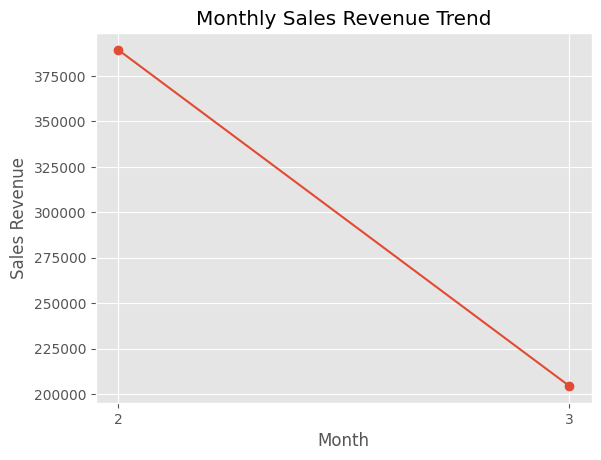

In [24]:
plt.plot(monthly_sales.index,monthly_sales.values,marker='o')
plt.xlabel('Month')
plt.ylabel('Sales Revenue')
plt.title('Monthly Sales Revenue Trend')
plt.xticks(monthly_sales.index)
plt.grid(True)
plt.show()

In [25]:
category_share=category_sales/category_sales.sum()
print('Product category revenue share:')
print((category_share*100).round(2).astype(str)+'%')


Product category revenue share:
Category
Sports         24.89%
Beauty         22.59%
Clothing       20.46%
Home           16.52%
Electronics    15.54%
Name: OrderValue, dtype: object


In [26]:
daily_sales_sorted=daily_sales.sort_index()
rolling_avg=daily_sales_sorted.rolling(window=7).mean()
print('7-day moving average sales:')
print(rolling_avg.head(10))

7-day moving average sales:
InvoiceDate
2009-01-12   NaN
2009-02-12   NaN
Name: TotalSales, dtype: float64


In [31]:
category_revenue=data_merged.groupby('Category')['OrderValue'].sum().sort_values(ascending=False)
top_category=category_revenue.index[0]
top_revenue=category_revenue.iloc[0]
print(f'The top-selling category is {top_category} with revenue of {top_revenue:,.2f}.')

The top-selling category is Sports with revenue of 147,783.07.


In [32]:
data.to_csv("cleaned_retail_analytics_project.csv", index=False)